# G8 — Entraînement de RT-DETR sur GTSDB (4 catégories)

## 1. Installation et vérification du GPU

In [1]:
!pip install -q -U ultralytics
!nvidia-smi

Wed Nov 18 08:03:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Copier les données et corriger `dataset.yaml`

In [2]:
import glob, os, shutil

# 1) retrouver la sortie du notebook 01_kaggle_data_prep (ajoutée en Input)
src = os.path.dirname(glob.glob('/kaggle/input/**/gtsdb_4cls/dataset.yaml', recursive=True)[0])
dst = '/kaggle/working/data/processed/gtsdb_4cls'
os.makedirs(os.path.dirname(dst), exist_ok=True)
shutil.copytree(src, dst, dirs_exist_ok=True)   # copie modifiable (l'input est en lecture seule)

# 2) corriger le chemin dans dataset.yaml (il pointait vers l'ancienne session)
lines = open(f'{dst}/dataset.yaml').read().splitlines()
lines[0] = f'path: {dst}'
open(f'{dst}/dataset.yaml', 'w').write('\n'.join(lines) + '\n')

YAML = f'{dst}/dataset.yaml'
print(open(YAML).read())
for sp in ['train', 'val', 'test']:
    print(sp, len(os.listdir(f'{dst}/images/{sp}')), 'images')   # attendu : 420 / 90 / 90

path: /kaggle/working/data/processed/gtsdb_4cls
train: images/train
val: images/val
test: images/test
names:
  0: prohibitory
  1: danger
  2: mandatory
  3: other

train 420 images
val 90 images
test 90 images


## 3. Test rapide (3 epochs, 640 px)
Si cette cellule se termine sans erreur et affiche des mAP, tout est bon. Les valeurs seront basses : c'est normal après 3 epochs.

In [ ]:
from ultralytics import RTDETR

# Test rapide : 3 epochs en 640 px. Sert à vérifier que tout fonctionne SANS gaspiller le quota GPU.
model = RTDETR('rtdetr-l.pt')    # poids pré-entraînés COCO (téléchargés automatiquement)
model.train(
    data=YAML, imgsz=640, epochs=3, batch=4, device=0, seed=42, workers=2,
    project='/kaggle/working/runs', name='rtdetr_test', exist_ok=True,
)

## 4. Entraînement complet (1280 px, jusqu'à 100 epochs)
RT-DETR est plus lourd que YOLO11 : comptez 1,5 à 3 h (estimation, dépend du GPU attribué). Ne lancez cette cellule qu'après le test rapide.

In [3]:
from ultralytics import RTDETR

# Entraînement complet. Les panneaux sont petits -> haute résolution (1280).
# batch=2 : le test à 640 px avec batch=4 a utilisé 3,8 Go ; à 1280 px la mémoire est ~4x plus grande.
# Si "CUDA out of memory" malgré tout : imgsz=1024 (pensez alors à évaluer avec --imgsz 1024).
model = RTDETR('rtdetr-l.pt')
model.train(
    data=YAML,
    imgsz=1280, epochs=100, patience=30, batch=2, device=0, workers=2,
    seed=42,
    fliplr=0.0,          # pas de miroir : "tourner à gauche" deviendrait "tourner à droite"
    close_mosaic=10,
    project='/kaggle/working/runs', name='rtdetr_full', exist_ok=True,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data/processed/gtsdb_4cls/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=tor

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      5.79G      1.005       9.19     0.3089          1       1280: 100% ━━━━━━━━━━━━ 210/210 2.1it/s 1:410.5sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 2.8it/s 8.2s0.3s
                   all         90        113      0.175      0.858       0.44      0.368

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size


/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/100      6.19G     0.5456     0.7124     0.2557          9       1280: 0% ──────────── 0/210  0.5s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (194 outputs left out)

     99/100      6.19G    0.08815     0.1709   0.009695          4       1280: 100% ━━━━━━━━━━━━ 210/210 2.2it/s 1:360.5sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.4it/s 6.9s0.3s
                   all         90        113      0.964      0.976      0.983      0.896

      Epoch    GPU_mem  giou_loss   cls_loss    l1_loss  Instances       Size
    100/100      6.19G    0.08938     0.1771   0.009379          1       1280: 0% ──────────── 0/210  0.4s

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


    100/100      6.19G    0.08817     0.1695   0.009118          1       1280: 100% ━━━━━━━━━━━━ 210/210 2.2it/s 1:360.4sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.4it/s 6.8s0.3s
                   all         90        113      0.984      0.971      0.984      0.898

100 epochs completed in 2.905 hours.
Optimizer stripped from /kaggle/working/runs/rtdetr_full/weights/last.pt, 66.5MB
Optimizer stripped from /kaggle/working/runs/rtdetr_full/weights/best.pt, 66.5MB

Validating /kaggle/working/runs/rtdetr_full/weights/best.pt...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 31,991,960 parameters, 0 gradients, 105.3 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 3.0it/s 7.6s0.3s
                   all         90        113      0.974      0.971      0.984      0.892


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a7c0cd19a90>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

## 5. Sauvegarder les poids et les courbes

In [4]:
import shutil
run = '/kaggle/working/runs/rtdetr_full'
shutil.copy(f'{run}/weights/best.pt', '/kaggle/working/rtdetr_best.pt')
for f in ['results.csv', 'results.png', 'confusion_matrix.png', 'PR_curve.png']:
    if os.path.exists(f'{run}/{f}'):
        shutil.copy(f'{run}/{f}', f'/kaggle/working/rtdetr_{f}')
print(os.listdir('/kaggle/working'))


['rtdetr-l.pt', 'runs', 'rtdetr_confusion_matrix.png', 'rtdetr_results.csv', 'rtdetr_results.png', '.virtual_documents', 'rtdetr_best.pt', 'data']


## 6. Contrôle sur le jeu de test

In [5]:
# Contrôle rapide sur le jeu de TEST (la comparaison finale se fera avec notre evaluate.py commun)
model = RTDETR('/kaggle/working/rtdetr_best.pt')
m = model.val(data=YAML, split='test', imgsz=1280, batch=4, device=0, conf=0.001, iou=0.5,
              project='/tmp/val', name='test', exist_ok=True)
print('mAP@0.5      :', round(m.box.map50, 3))
print('mAP@0.5:0.95 :', round(m.box.map, 3))
print('précision    :', round(m.box.mp, 3), '| rappel :', round(m.box.mr, 3))

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
rt-detr-l summary (fused): 315 layers, 31,991,960 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 126.7±38.7 MB/s, size: 1237.3 KB)
val: Scanning /kaggle/working/data/processed/gtsdb_4cls/labels/test... 90 images, 7 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 90/90 110.5it/s 0.8s0.1s
val: New cache created: /kaggle/working/data/processed/gtsdb_4cls/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 1.1s/it 24.2s1.0ss
                   all         90        150      0.992      0.971      0.992      0.891
           prohibitory         27         49      0.995          1      0.995       0.92
                danger         26         33      0.989          1      0.995      0.903
             mandatory         25         28      0.983      0.929      0.985      0.873
                 oth

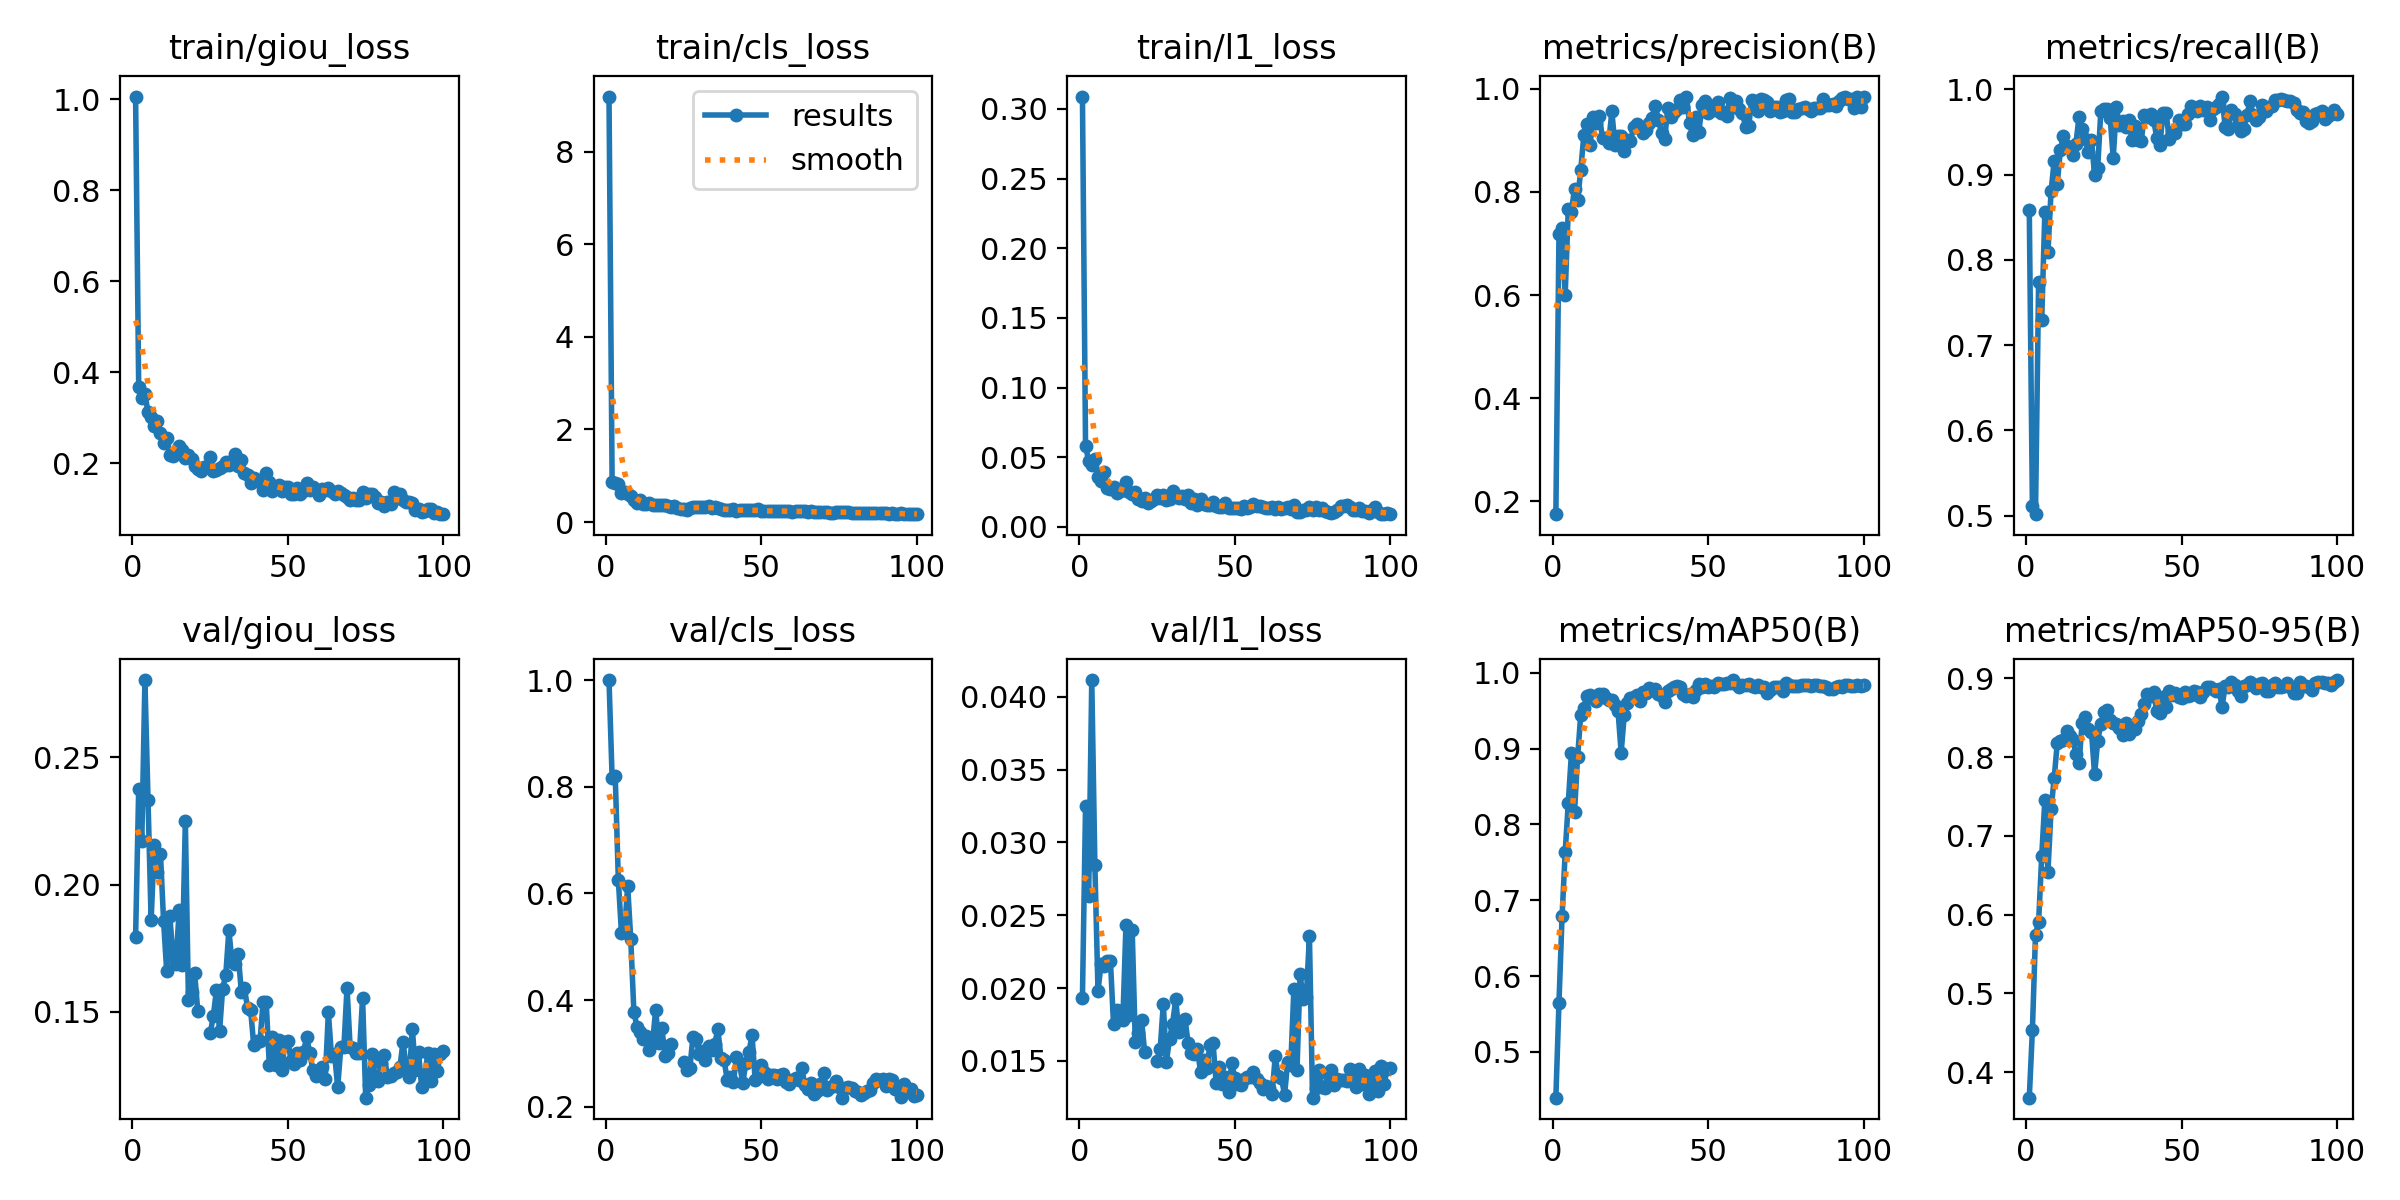

In [6]:
from IPython.display import Image, display
display(Image('/kaggle/working/rtdetr_results.png'))

## 6 bis. Nettoyage (à faire en dernier)
Supprime les dossiers lourds pour que l'Output ne contienne que les poids et les courbes.

In [ ]:
import shutil
shutil.rmtree('/kaggle/working/runs', ignore_errors=True)
shutil.rmtree('/kaggle/working/data', ignore_errors=True)
print(os.listdir('/kaggle/working'))